In [1]:

%pip -q install qiskit matplotlib numpy



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 1.9 MB/s eta 0:00:00


In [2]:

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

qc = QuantumCircuit(1)
qc.h(0)

print(qc.draw())
print(Statevector.from_instruction(qc).probabilities_dict())


   ┌───┐
q: ┤ H ├
   └───┘
{np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


In [3]:

import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# Reproducible experiments
rng = np.random.default_rng(42)

print("QuantumShield: BB84 simulation ready")



QuantumShield: BB84 simulation ready


In [4]:

def prepare_qubit(bit, basis):
    """Prepare one BB84 qubit using Qiskit."""
    qc = QuantumCircuit(1)

    if bit == 1:
        qc.x(0)

    if basis == 1:
        qc.h(0)

    return qc


def measure_qubit(qc, basis, rng):
    """Simulate measurement in the requested basis."""
    measured = qc.copy()

    if basis == 1:
        measured.h(0)

    probabilities = Statevector.from_instruction(
        measured
    ).probabilities()

    return int(rng.choice([0, 1], p=probabilities))


def transmit_bit(bit, alice_basis, bob_basis,
                 eve_present, rng):
    """Transmit a single BB84 qubit, optionally intercepted."""
    qc = prepare_qubit(bit, alice_basis)

    if eve_present:
        eve_basis = int(rng.integers(0, 2))
        eve_bit = measure_qubit(qc, eve_basis, rng)

        # Eve resends the state she measured.
        qc = prepare_qubit(eve_bit, eve_basis)

    return measure_qubit(qc, bob_basis, rng)


In [5]:

def run_bb84(n_bits=1000, eve_present=False, seed=42):
    rng = np.random.default_rng(seed)

    alice_bits = rng.integers(0, 2, n_bits)
    alice_bases = rng.integers(0, 2, n_bits)
    bob_bases = rng.integers(0, 2, n_bits)

    bob_bits = np.array([
        transmit_bit(
            int(alice_bits[i]),
            int(alice_bases[i]),
            int(bob_bases[i]),
            eve_present,
            rng
        )
        for i in range(n_bits)
    ])

    # Keep only positions where the bases match.
    sifted = alice_bases == bob_bases
    alice_key = alice_bits[sifted]
    bob_key = bob_bits[sifted]

    qber = np.mean(alice_key != bob_key) * 100

    return {
        "transmitted": n_bits,
        "sifted_bits": int(sifted.sum()),
        "qber_percent": float(qber),
        "alice_key": alice_key,
        "bob_key": bob_key,
    }


normal = run_bb84(eve_present=False, seed=42)
attacked = run_bb84(eve_present=True, seed=42)

print("WITHOUT EAVESDROPPING")
print("Sifted bits:", normal["sifted_bits"])
print("QBER:", normal["qber_percent"], "%")

print("\nWITH EAVESDROPPING")
print("Sifted bits:", attacked["sifted_bits"])
print("QBER:", attacked["qber_percent"], "%")


WITHOUT EAVESDROPPING
Sifted bits: 501
QBER: 0.0 %

WITH EAVESDROPPING
Sifted bits: 501
QBER: 26.546906187624753 %


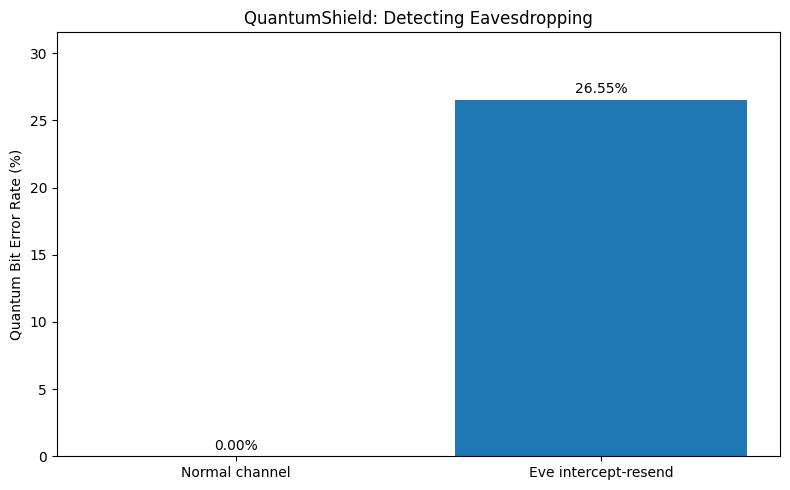

In [6]:

labels = ["Normal channel", "Eve intercept-resend"]
values = [
    normal["qber_percent"],
    attacked["qber_percent"]
]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values)

plt.ylabel("Quantum Bit Error Rate (%)")
plt.title("QuantumShield: Detecting Eavesdropping")
plt.ylim(0, max(30, max(values) + 5))

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


MEAN RESULTS ACROSS 20 TRIALS
                         sifted_bits  qber_percent
scenario                                          
Intercept-resend attack        499.6         24.99
Normal channel                 499.6          0.00


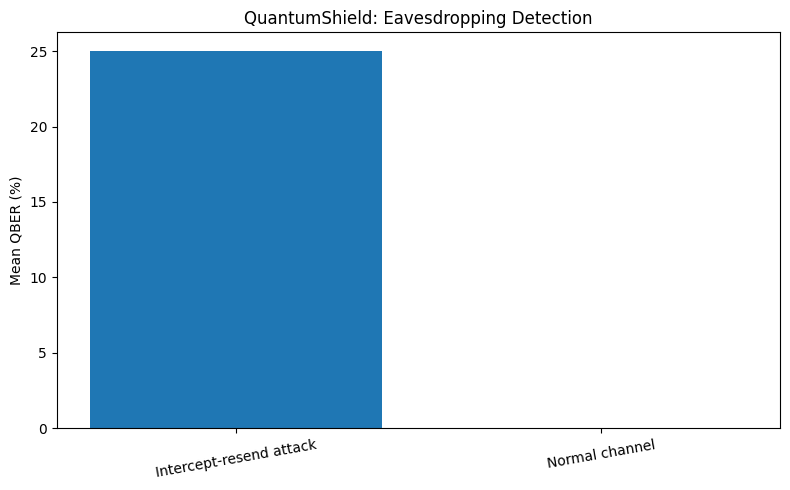

Saved results CSV and chart.


In [7]:

import pandas as pd
import matplotlib.pyplot as plt

# Run independent experiments with different random seeds.
records = []

for trial in range(20):
    for eve_present in [False, True]:
        result = run_bb84(
            n_bits=1000,
            eve_present=eve_present,
            seed=1000 + trial
        )

        records.append({
            "trial": trial + 1,
            "scenario": (
                "Intercept-resend attack"
                if eve_present else "Normal channel"
            ),
            "transmitted_bits": result["transmitted"],
            "sifted_bits": result["sifted_bits"],
            "qber_percent": result["qber_percent"]
        })

df = pd.DataFrame(records)

print("MEAN RESULTS ACROSS 20 TRIALS")
print(
    df.groupby("scenario")[
        ["sifted_bits", "qber_percent"]
    ].mean().round(2)
)

df.to_csv("quantumshield_results.csv", index=False)

summary = df.groupby("scenario")["qber_percent"].mean()

plt.figure(figsize=(8, 5))
plt.bar(summary.index, summary.values)
plt.ylabel("Mean QBER (%)")
plt.title("QuantumShield: Eavesdropping Detection")
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig("quantumshield_results.png", dpi=200)
plt.show()

print("Saved results CSV and chart.")
